# Visualización de tablas e imágenes

Retomaremos los archivos de las sesiones 2 y 3 para representar edades, comparar proporciones y mostrar imágenes. Usaremos Matplotlib, una biblioteca para crear gráficos en Python.

## Contenido
1. Figura, área de dibujo e histograma.
2. Comparación de grupos con barras.
3. Imágenes de CIFAR-10 y exportación.

Los dos ejercicios están dentro de esta notebook.

In [4]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "pyproject.toml").exists():
    raise FileNotFoundError("Open the notebook from the session project directory")
passengers = pd.read_csv(
    project_dir.parent / "sesion-02-pandas/outputs/passengers_prepared.csv"
)
image_dir = project_dir.parent / "sesion-03-pytorch/outputs"
images = np.load(image_dir / "images.npy", allow_pickle=False)
labels = np.load(image_dir / "labels.npy", allow_pickle=False)
report = json.loads((image_dir / "report.json").read_text())
print(passengers.shape, images.shape)

(891, 12) (64, 3, 32, 32)


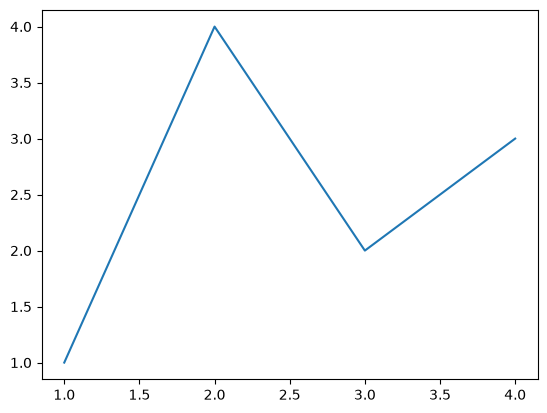

In [11]:
fig, ax = plt.subplots()             # Create a figure containing a single Axes.
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Plot some data on the Axes.
plt.show()                           # Show the figure.

Text(0, 0.5, 'entry b')

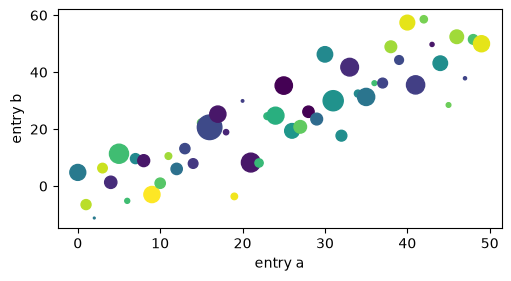

In [13]:
np.random.seed(19680801)  # seed the random number generator.
data = {'a': np.arange(50),
        'c': np.random.randint(0, 50, 50),
        'd': np.random.randn(50)}
data['b'] = data['a'] + 10 * np.random.randn(50)
data['d'] = np.abs(data['d']) * 100

fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.scatter('a', 'b', c='c', s='d', data=data)
ax.set_xlabel('entry a')
ax.set_ylabel('entry b')

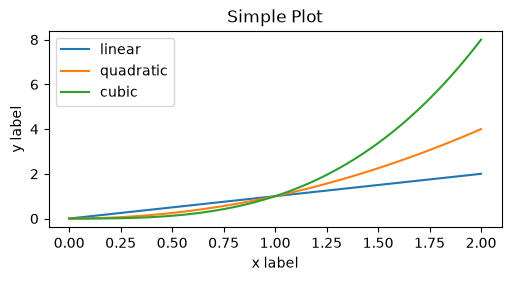

In [14]:
x = np.linspace(0, 2, 100)  # Sample data.

# Note that even in the OO-style, we use `.pyplot.figure` to create the Figure.
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.plot(x, x, label='linear')  # Plot some data on the Axes.
ax.plot(x, x**2, label='quadratic')  # Plot more data on the Axes...
ax.plot(x, x**3, label='cubic')  # ... and some more.
ax.set_xlabel('x label')  # Add an x-label to the Axes.
ax.set_ylabel('y label')  # Add a y-label to the Axes.
ax.set_title("Simple Plot")  # Add a title to the Axes.
ax.legend()  # Add a legend.

## 1. Figura e histograma

`plt.subplots()` crea una **Figure** (`fig`), que contiene el gráfico, y un **Axes** (`ax`), el área donde dibujamos. `figsize` expresa el tamaño en pulgadas y `layout="constrained"` ajusta el espacio para títulos y etiquetas.

Un histograma agrupa valores numéricos en intervalos. `bins=10` divide el rango en diez intervalos y la altura cuenta pasajeros. Usamos `Age`, la edad original, y omitimos sus ausentes con `dropna()`. Graficar `age_filled` mezclaría edades registradas con reemplazos.

In [15]:
ages = passengers["Age"].dropna()
type(passengers["Age"])

pandas.Series

Recorded ages: 714; missing: 177


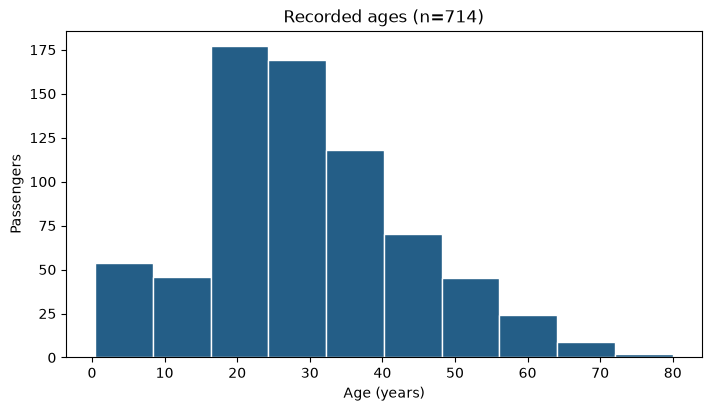

In [16]:
ages = passengers["Age"].dropna()
print(f"Recorded ages: {len(ages)}; missing: {passengers['Age'].isna().sum()}")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(ages, bins=10, color="#245E87", edgecolor="white")
ax.set_title(f"Recorded ages (n={len(ages)})")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Passengers")
plt.show()

### Ejercicio 1 · Cambiar los intervalos

Repite el histograma con `bins=20`, conservando los mismos datos y etiquetas. Describe en dos frases qué detalles se distinguen mejor y por qué cambiar los intervalos no cambia la cantidad de edades disponibles.

Recorded ages: 714; missing: 177


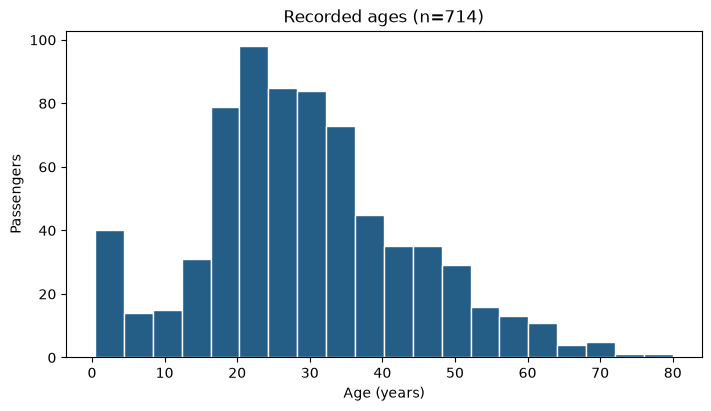

In [ ]:
#Ejercicio 1: Visualización de datos
# Write your histogram here.

ages = passengers["Age"].dropna()
print(f"Recorded ages: {len(ages)}; missing: {passengers['Age'].isna().sum()}")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(ages, bins=20, color="#245E87", edgecolor="white")
ax.set_title(f"Recorded ages (n={len(ages)})")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Passengers")
plt.show()

#Explicacion:

'''
Los detalles que mejoran la visualización del histograma son:
1. **Número de bins**: Se ha aumentado el número de bins de 10 a 20, lo que permite una representación más detallada de la distribución de edades.
2. **Color y borde**: Se ha mantenido un color consistente (#245E87) y se ha añadido un borde blanco a cada barra, lo que mejora la claridad visual y hace que las barras sean más distinguibles.
3. **Etiquetas y título**: Se han añadido etiquetas claras para los ejes y un título descriptivo que incluye el número de registros, lo que proporciona contexto adicional al lector sobre la cantidad de datos representados en el histograma. 
4. **Espaciado y diseño**: Se ha utilizado un diseño con espacio adecuado entre los elementos, lo que mejora la legibilidad y la estética general del gráfico.

Ademas, cambiar los intervalos de los bins permite observar mejor la distribución de edades, especialmente si hay concentraciones en ciertos rangos de edad. 
Esto puede ayudar a identificar patrones o tendencias en los datos que podrían no ser evidentes con un número menor de bins. Y no cambia la cantidad de 
edades disponibles, solo la forma en que se agrupan para la visualización.

'''


## 2. Comparación con barras

Las barras comparan categorías. La media de `Survived`, que contiene ceros y unos, es la proporción de supervivientes de cada grupo. Multiplicamos por 100 para mostrar porcentajes y conservamos el tamaño de cada grupo en las etiquetas.

El eje vertical empieza en cero y termina en 100. Estas proporciones describen el archivo, sin demostrar que la clase por sí sola explique la supervivencia.

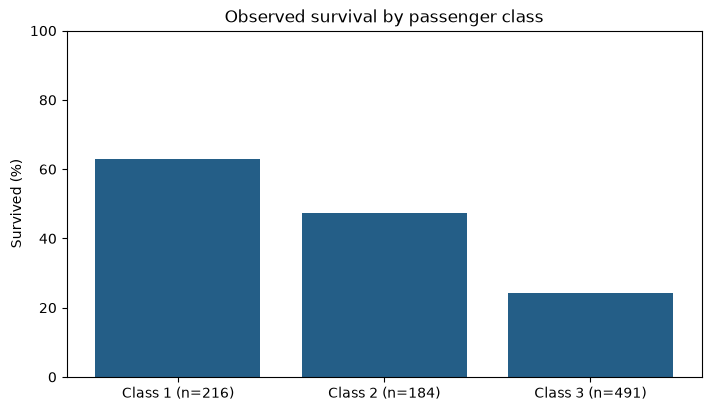

In [7]:
summary = passengers.groupby("Pclass")["Survived"].agg(["mean", "size"])
class_names = [f"Class {i} (n={n})" for i, n in summary["size"].items()]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.bar(class_names, summary["mean"] * 100, color="#245E87")
ax.set_title("Observed survival by passenger class")
ax.set_ylabel("Survived (%)")
ax.set_ylim(0, 100)
plt.show()

### Ejercicio 2 · Edades ausentes por clase

Agrupa por `Pclass` y calcula el porcentaje de valores `True` en `age_missing`. Dibuja barras con las tres clases, título, etiqueta vertical y escala de 0 a 100. Usa la operación de agrupación del ejemplo anterior como guía.

Indica qué clase tiene el mayor porcentaje y por qué ese resultado es distinto de contar únicamente cuántas edades faltan.

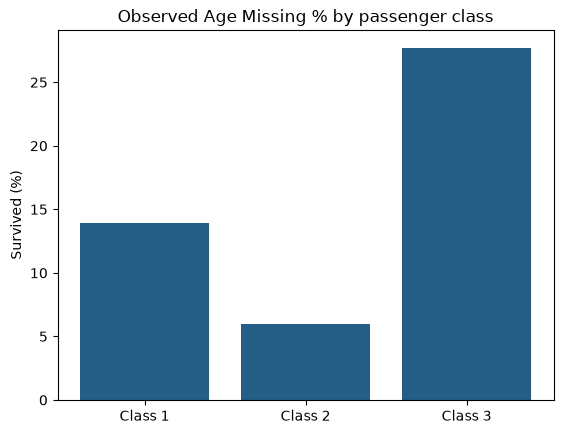

In [24]:
#Ejercicio 2: Visualización de datos
# Calculate the percentages and draw the bars here.

summary = passengers.groupby("Pclass")["age_missing"].mean()*100
# class_names = [f"Class {i} (n={n})" for i, n in summary["size"].items()]
class_names = ["Class 1", "Class 2", "Class 3"]
fig, ax = plt.subplots()
# fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
# ax.bar(class_names, summary["mean"] * 100, color="#245E87")
ax.bar(class_names, summary, color="#245E87")
ax.set_title("Observed Age Missing % by passenger class")
ax.set_ylabel("Survived (%)")
# ax.set_ylim(0, 100)
plt.show()

## 3. Imágenes de CIFAR-10

Los archivos guardan imágenes como `(N, C, H, W)` con valores entre 0 y 1. `imshow` espera una imagen RGB como `(H, W, C)`. `transpose(1, 2, 0)` mueve los ejes de una imagen de CHW a HWC; `reshape` no intercambia esos ejes.

`subplots(2, 4)` crea ocho áreas de dibujo. `axes.flat` permite recorrerlas una por una y `enumerate` añade el índice. Ocultamos los ejes y usamos la etiqueta real de cada imagen como título. `interpolation="nearest"` permite observar los píxeles originales.

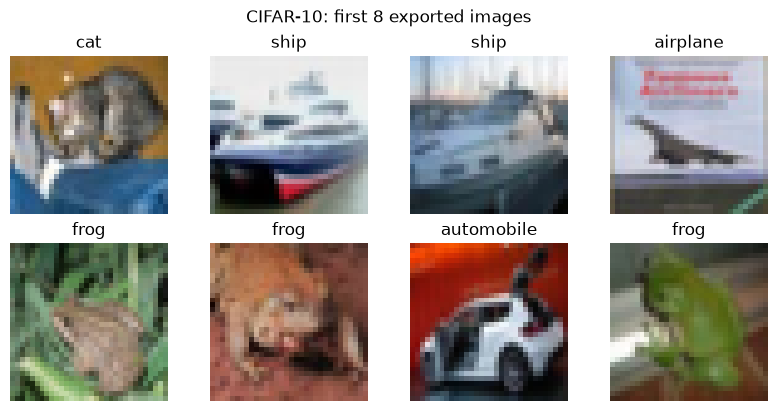

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(8, 4), layout="constrained")
for index, ax in enumerate(axes.flat):
    ax.axis("off")
    if index < len(images):
        image = images[index].transpose(1, 2, 0)
        ax.imshow(image, interpolation="nearest")
        ax.set_title(report["classes"][int(labels[index])])
fig.suptitle(f"CIFAR-10: first {min(8, len(images))} exported images")
plt.show()

### Guardar una figura

`fig.savefig` guarda esa figura, aunque ya la hayamos mostrado. `dpi` controla la resolución del PNG. Las imágenes pertenecen a la selección exportada en la sesión 3; sus frecuencias no describen necesariamente todo CIFAR-10.

In [10]:
output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)
fig.savefig(output_dir / "cifar_grid.png", dpi=150)
print(output_dir / "cifar_grid.png")

/mnt/d/ArchLinuxData/Documentos/FMAT - MAESTRIA IA/Maestria-IA---FMAT/Programación para IA/actividaes/Unidad_2/sesion-04-visualizacion/outputs/cifar_grid.png


### De la notebook al proyecto

`main.py` reúne los tres ejemplos y guarda sus figuras. `plt.close(fig)` libera cada figura después de guardarla cuando ejecutamos el programa desde la terminal.

```bash
uv run --locked python main.py
```

Antes de interpretar un gráfico, identifica qué datos incluye, qué representa cada eje y cuál es el denominador de sus porcentajes.

[Documentación oficial y fuentes](./FUENTES.md)